# EDA 04: không gian và thời gian

Dữ liệu nằm ở đâu, giả thuyết múi giờ có đúng không, dữ liệu phân bố theo tháng, năm thế nào.

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 9 | Dữ liệu nằm ở đâu? | Phạm vi, múi giờ (A9) |
| 10 | Giả thuyết múi giờ có đúng không (trong và ngoài Trung Quốc)? | Đổi giờ địa phương (A1, A9) |
| 11 | Dữ liệu phân bố thế nào theo tháng, năm? Nhịp theo giờ có đổi qua các năm không? | Mô phỏng drift (CP3) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`). Mục được đánh số liên tục 1–13 xuyên các notebook; xem bảng ở README.

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 04 mục 10. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = split.dev_users()   # nhóm dev (D17); đặt None để chạy mọi user (không dùng để chọn ngưỡng)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=['space_time'], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A
months = R.months
print(f"{len(users)} user, {len(files):,} file")

[20/122] đã đọc tới user 031 (6 giây)
[40/122] đã đọc tới user 058 (10 giây)
[60/122] đã đọc tới user 091 (12 giây)
[80/122] đã đọc tới user 117 (13 giây)
[100/122] đã đọc tới user 147 (16 giây)
[120/122] đã đọc tới user 177 (19 giây)
[122/122] đã đọc tới user 179 (19 giây)
122 user, 13,022 file


## 9. Phân bố không gian

**Câu hỏi:** dữ liệu nằm ở đâu? Bao nhiêu phần trăm ở Bắc Kinh, ở Trung Quốc, ở nước ngoài? Phần ngoài Trung Quốc cần cách đổi múi giờ khác.

Vùng Bắc Kinh và Trung Quốc là hình chữ nhật xấp xỉ (xem `BJ_BOX`, `CN_BOX`), đủ cho mục đích thống kê.

In [2]:
n = users["n_points"].sum()
n_bj = users["n_in_bj"].sum()
n_out = users["n_outside_cn"].sum()
print(f"Trong Bắc Kinh:        {n_bj:>12,}  ({pct(n_bj, n):.2f}%)")
print(f"Trung Quốc, ngoài BK:  {n - n_bj - n_out:>12,}  ({pct(n - n_bj - n_out, n):.2f}%)")
print(f"Ngoài Trung Quốc:      {n_out:>12,}  ({pct(n_out, n):.2f}%)")
print(f"User có điểm ngoài Trung Quốc: {(users['n_outside_cn'] > 0).sum()}")
print(f"User có dưới 50% điểm ở Bắc Kinh: {(users['share_bj'] < 0.5).sum()}")

Trong Bắc Kinh:          13,396,699  (79.46%)
Trung Quốc, ngoài BK:     3,139,027  (18.62%)
Ngoài Trung Quốc:           323,718  (1.92%)
User có điểm ngoài Trung Quốc: 7
User có dưới 50% điểm ở Bắc Kinh: 14


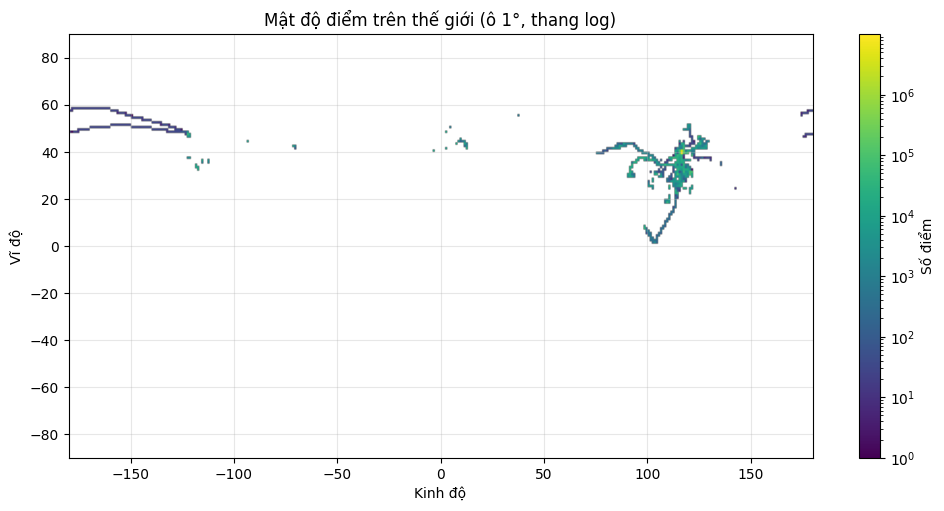

In [3]:
fig, ax = plt.subplots(figsize=(12, 5.5))
w = np.ma.masked_equal(A["world"], 0)
im = ax.imshow(w, origin="lower", extent=[-180, 180, -90, 90], norm=LogNorm(), cmap="viridis", aspect="auto")
ax.set_xlabel("Kinh độ"); ax.set_ylabel("Vĩ độ")
ax.set_title("Mật độ điểm trên thế giới (ô 1°, thang log)")
ax.grid(alpha=0.3)
plt.colorbar(im, ax=ax, label="Số điểm")
plt.show()

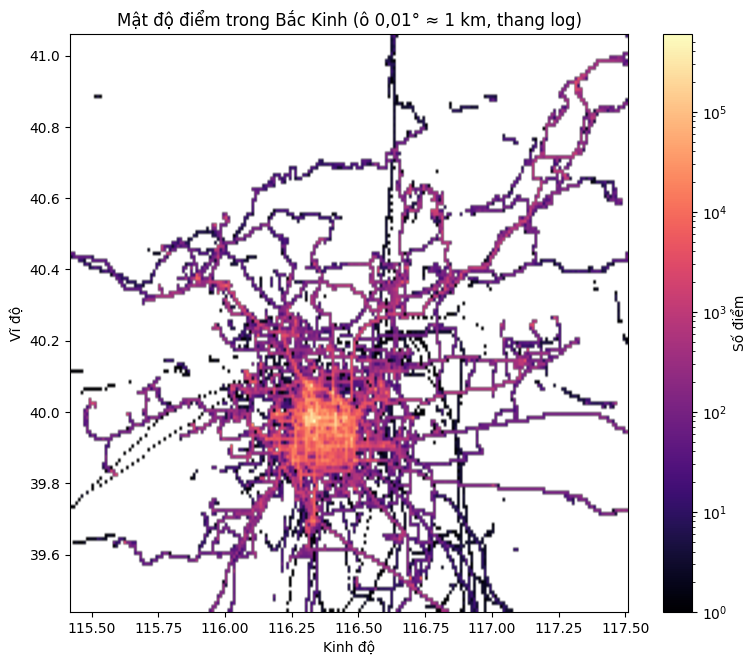

In [4]:
fig, ax = plt.subplots(figsize=(9, 7.5))
b = np.ma.masked_equal(A["bj"], 0)
im = ax.imshow(b, origin="lower", extent=[BJ_BOX[2], BJ_BOX[3], BJ_BOX[0], BJ_BOX[1]],
               norm=LogNorm(), cmap="magma", aspect="auto")
ax.set_xlabel("Kinh độ"); ax.set_ylabel("Vĩ độ")
ax.set_title("Mật độ điểm trong Bắc Kinh (ô 0,01° ≈ 1 km, thang log)")
plt.colorbar(im, ax=ax, label="Số điểm")
plt.show()

In [5]:
users[users["share_bj"] < 0.5][["user", "n_points", "share_bj", "share_cn", "lat_med", "lon_med"]].sort_values("share_bj")

,user,n_points,share_bj,share_cn,lat_med,lon_med
12,021,2385,0.039832,1.000000,28.912567,116.960700
84,124,120111,0.089992,1.000000,35.168456,93.050563
92,137,14245,0.117726,1.000000,33.539045,115.793093
100,148,41830,0.141788,1.000000,35.345069,114.336062
81,120,10789,0.256001,1.000000,42.136412,117.259290
5,010,931815,0.275348,1.000000,37.689265,116.312583
75,111,15326,0.279460,1.000000,36.590542,105.660492
64,099,1267,0.352013,1.000000,34.731883,116.300333
111,162,339,0.410029,1.000000,39.119033,117.161150
17,027,15508,0.410756,1.000000,33.322992,116.298553


## 10. Kiểm chứng múi giờ

**Giả thuyết:** timestamp là UTC (User Guide), và giờ địa phương trong Trung Quốc là UTC+8.

**Cách kiểm chứng:** chỉ xét điểm trong Trung Quốc. Nếu giả thuyết đúng, theo giờ địa phương số điểm sẽ thấp nhất vào khoảng 1–5 giờ sáng và cao vào giờ đi làm, đi về. Nếu theo UTC mà biểu đồ mới trông hợp lý, thì timestamp thực ra đã là giờ địa phương. Kết quả mục này quyết định mục 2, 12 và 13 có đọc được hay không.

Phần sau kiểm tra riêng cách xấp xỉ `round(lon / 15)` cho điểm **ngoài Trung Quốc** theo cùng cách đọc. Số điểm ở đây ít và tập trung ở vài user, nên chỉ đủ để thấy có lệch rõ hay không, không đủ để kiểm chứng chặt.


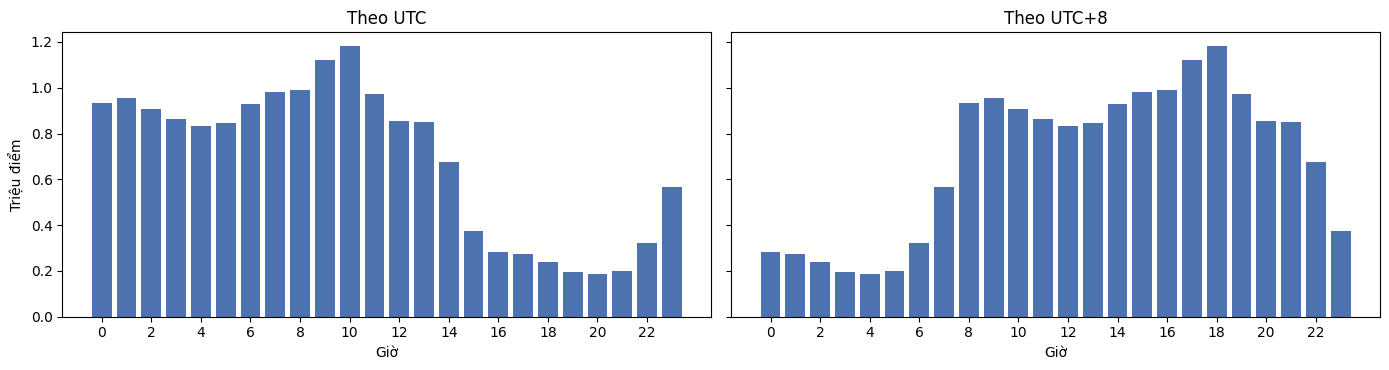

hour_utc_cn: ít nhất lúc 20h, nhiều nhất lúc 10h, 3 giờ thấp nhất: [19, 20, 21]
hour_loc_cn: ít nhất lúc 4h, nhiều nhất lúc 18h, 3 giờ thấp nhất: [3, 4, 5]


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, key, title in ((axes[0], "hour_utc_cn", "Theo UTC"), (axes[1], "hour_loc_cn", "Theo UTC+8")):
    ax.bar(range(24), A[key] / 1e6, color="#4c72b0")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Giờ"); ax.set_title(title)
axes[0].set_ylabel("Triệu điểm")
plt.tight_layout()
plt.show()
for key in ("hour_utc_cn", "hour_loc_cn"):
    h = A[key]
    print(f"{key}: ít nhất lúc {int(np.argmin(h))}h, nhiều nhất lúc {int(np.argmax(h))}h, "
          f"3 giờ thấp nhất: {sorted(np.argsort(h)[:3].tolist())}")

Điểm ngoài Trung Quốc: 323,718 ở 7 user


,user,n_points,n_outside_cn,share_cn,lat_med,lon_med
105,153,2156964,176506,0.918169,39.966842,116.448766
96,144,582833,67914,0.883476,39.906117,116.346454
53,082,172543,31971,0.814707,40.052341,116.380489
94,140,342496,22612,0.933979,39.989808,116.406532
87,128,1208309,20655,0.982906,40.021640,116.329775
54,084,401332,4048,0.989914,39.947951,116.350305
9,017,1026176,12,0.999988,39.980653,116.358798


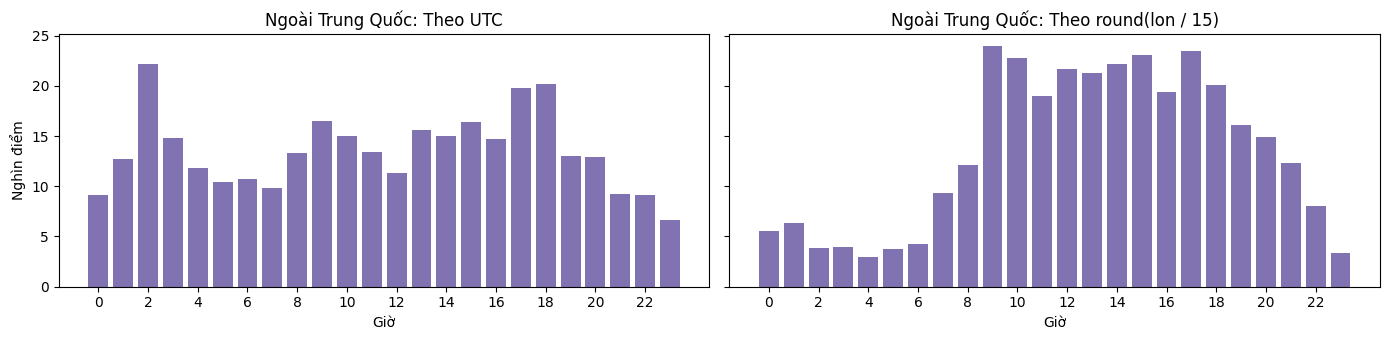

hour_utc_out: 3 giờ thấp nhất: [0, 22, 23], nhiều nhất lúc 2h
hour_loc_out: 3 giờ thấp nhất: [4, 5, 23], nhiều nhất lúc 9h


In [7]:
n_out = int(A["hour_loc_out"].sum())
out_users = users[users["n_outside_cn"] > 0].sort_values("n_outside_cn", ascending=False)
print(f"Điểm ngoài Trung Quốc: {n_out:,} ở {len(out_users)} user")
display(out_users[["user", "n_points", "n_outside_cn", "share_cn", "lat_med", "lon_med"]])
if n_out:
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
    for ax, key, title in ((axes[0], "hour_utc_out", "Theo UTC"), (axes[1], "hour_loc_out", "Theo round(lon / 15)")):
        ax.bar(range(24), A[key] / 1e3, color="#8172b2")
        ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Giờ"); ax.set_title(f"Ngoài Trung Quốc: {title}")
    axes[0].set_ylabel("Nghìn điểm")
    plt.tight_layout()
    plt.show()
    for key in ("hour_utc_out", "hour_loc_out"):
        h = A[key]
        print(f"{key}: 3 giờ thấp nhất: {sorted(np.argsort(h)[:3].tolist())}, nhiều nhất lúc {int(np.argmax(h))}h")


## 11. Phân bố theo thời gian (tháng)

**Câu hỏi:** dữ liệu trải từ 04/2007 đến 08/2012 có đều không? Checkpoint 3 cần mô phỏng drift trên dữ liệu tĩnh: một cách là chia theo thời gian (ví dụ train trên 2008, "production" trên 2009+) và so sánh phân phối. Biểu đồ này cho biết giai đoạn nào đủ dữ liệu để làm vậy.

Phần sau xem **nhịp theo giờ có đổi qua các năm không**: mỗi hàng là một năm, chuẩn hóa trong năm đó. Nếu hình dạng đổi rõ (ví dụ năm sau ít dữ liệu ban đêm hơn), đó là một dạng drift có sẵn trong dữ liệu.

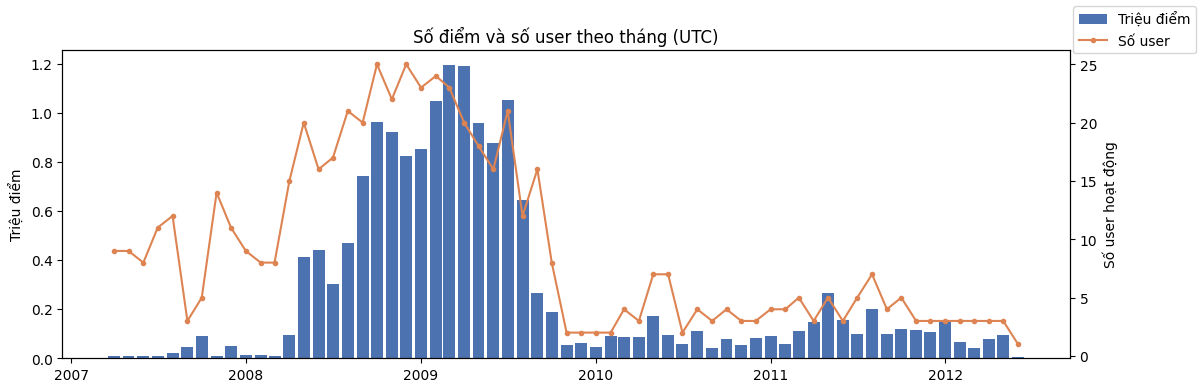

năm,2007,2008,2009,2010,2011,2012
% số điểm theo năm,1.5,30.9,49.8,6.0,9.3,2.5


In [8]:
mth = months.copy()
mth["month"] = pd.to_datetime(mth["month"])
fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.bar(mth["month"], mth["n_points"] / 1e6, width=25, color="#4c72b0", label="Triệu điểm")
ax1.set_ylabel("Triệu điểm")
ax2 = ax1.twinx()
ax2.plot(mth["month"], mth["n_users"], color="#dd8452", marker=".", label="Số user")
ax2.set_ylabel("Số user hoạt động")
ax1.set_title("Số điểm và số user theo tháng (UTC)")
fig.legend(loc="upper right")
plt.show()
yr = mth.groupby(mth["month"].dt.year)["n_points"].sum().rename_axis("năm")
(yr / yr.sum() * 100).round(1).rename("% số điểm theo năm").to_frame().T

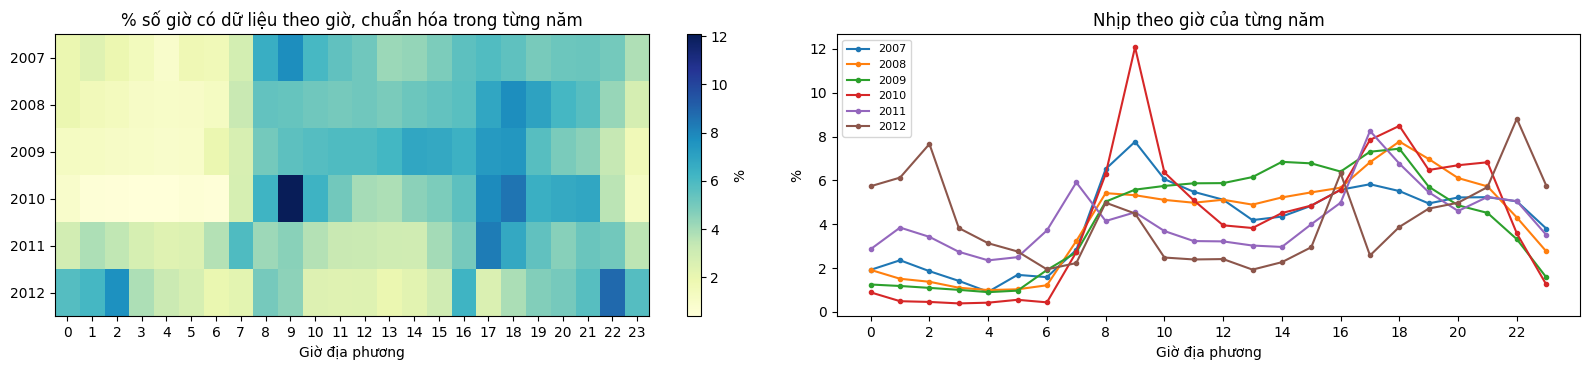

Tổng số giờ có dữ liệu mỗi năm:


năm,2007,2008,2009,2010,2011,2012
giờ,508.0,4575.0,7363.0,990.0,1002.0,284.0


In [9]:
yh = pd.DataFrame(A["year_hour"] / 60, index=pd.Index(A["years"], name="năm"), columns=range(24))
yh_share = yh.div(yh.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
im = axes[0].imshow(yh_share.to_numpy(), aspect="auto", cmap="YlGnBu")
axes[0].set_yticks(range(len(yh))); axes[0].set_yticklabels(yh.index)
axes[0].set_xticks(range(24)); axes[0].set_xlabel("Giờ địa phương")
axes[0].set_title("% số giờ có dữ liệu theo giờ, chuẩn hóa trong từng năm")
plt.colorbar(im, ax=axes[0], label="%")
for y, row in yh_share.iterrows():
    axes[1].plot(range(24), row.to_numpy(), marker=".", label=str(y))
axes[1].set_xticks(range(0, 24, 2)); axes[1].set_xlabel("Giờ địa phương"); axes[1].set_ylabel("%")
axes[1].set_title("Nhịp theo giờ của từng năm"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Tổng số giờ có dữ liệu mỗi năm:")
yh.sum(axis=1).round(0).to_frame("giờ").T
